# Model C — NLP Startup Idea Evaluator (PyTorch text encoder + transparent rule-based aspect findings)

**Part of:** Startup Idea Failure Prediction and Recommendation System

## What this dataset can and cannot support
The provided data (`venturematch_startups_10k_enriched_ckpt_.csv`) has **no outcome label and no idea-quality / aspect label**. The only text-linked label that is meaningful is `sector`. Therefore, following the project plan ("*do not present an arbitrary heuristic score as a validated ML prediction*"):

| Component | What it is | Validation status |
|---|---|---|
| **Neural text encoder** (PyTorch BiGRU + attention) | Trained on `sector` to learn idea embeddings | **Validated** on a held-out group split (accuracy, macro-F1, calibration) |
| Sector-consistency check | Compares the user's declared industry with the NN's text-based prediction | Validated only as far as the sector accuracy above |
| Similar-startup retrieval (embeddings) | Nearest neighbours in the training corpus | Exploratory; checked against `competitors_count` (result reported honestly) |
| **Aspect findings** (problem, customer, solution, validation, differentiation, business model, feasibility, demand) | Transparent regex/lexicon rules that quote supporting text and list missing information | **NOT validated. No scores are produced.** Statuses are only "evidence found / partial / not stated" |

## Confirmed design decisions
* NN purpose: text encoder / embeddings; aspect findings from transparent rules; **no predictive scores**.
* Framework: **PyTorch**.
* `business_model` and `stage` are **not** used as targets (they are almost unpredictable from the text); `sector` is the only supervised target.
* `ARR`, `BURN_RATE`, `VALUE`, `ask_usd`, `stage`, `business_model`, `keywords` are **not model inputs** (derived from other fields / not collected by the form / leakage). `competitors_count` is used only to *check* the similarity signal.

## Limitations stated up front
* Text is short, templated and appears synthetic (~14-word pitches). Real founder descriptions are longer and differently worded, so the encoder is **out-of-distribution** for them. The inference code chunks long text and raises warnings (high out-of-vocabulary rate, low confidence, too short).
* **Text alone cannot establish market demand.** "Not stated" in the findings means "the text does not say", not "the idea is weak".

## 1. Import libraries and configuration

In [1]:
import os, re, glob, json, math, random, warnings, textwrap, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 50)

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- NN / training configuration ----
MAX_LEN      = 64        # max tokens per chunk fed to the encoder
CHUNK_TOKENS = 48        # long user text is split into chunks of about this many tokens
MIN_FREQ     = 2         # vocabulary: minimum token frequency (train only)
EMB_DIM, HIDDEN, EMBED_DIM, DROPOUT = 128, 128, 128, 0.3
BATCH_SIZE, MAX_EPOCHS, PATIENCE = 128, 40, 6
LR, WEIGHT_DECAY, LABEL_SMOOTH, WORD_DROPOUT = 2e-3, 1e-2, 0.05, 0.10

# ---- inference guard rails ----
LOW_CONF, OOV_WARN, MIN_WORDS_WARN = 0.50, 0.35, 15

OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Device:", DEVICE, "| torch", torch.__version__, "| output:", OUTPUT_DIR)

Device: cpu | torch 2.11.0+cpu | output: /kaggle/working


## 2. Load the dataset (Kaggle input path)

In [2]:
csv_candidates = glob.glob("/kaggle/input/**/*.csv", recursive=True)
print("CSV files found:", csv_candidates)
assert csv_candidates, "No CSV found under /kaggle/input - add the dataset via 'Add Input'."
pref = [p for p in csv_candidates if "venturematch" in os.path.basename(p).lower()]
DATA_PATH = (pref or csv_candidates)[0]
print("Using:", DATA_PATH)

raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head(3)

CSV files found: ['/kaggle/input/datasets/mananpatel7310/venturematch-startups-10k-enriched-ckpt/venturematch_startups_10k_enriched_ckpt .csv']
Using: /kaggle/input/datasets/mananpatel7310/venturematch-startups-10k-enriched-ckpt/venturematch_startups_10k_enriched_ckpt .csv
Shape: (10000, 15)


,entity_type,name,sector,stage,business_model,ask_usd,keywords,pitch,elevator_speech,entity_id,text_profile,competitors_count,ARR,BURN_RATE,VALUE
0,startup,Zephyrion,SaaS,Pre-Seed,Enterprise,700000,"supply chain optimization, efficiency, productivity","Streamline your supply chain with our AI-driven platform that analyzes data from suppliers, warehouses, and retailers to reduce costs an...",Optimize supply chains for efficiency. We’re raising to ship product and win early customers.,ST_00001,"Streamline your supply chain with our AI-driven platform that analyzes data from suppliers, warehouses, and retailers to reduce costs an...",9.0,70000.0,6000.0,2100000.0
1,startup,NovaGrid,HealthTech,Seed,B2C,750000,"health monitoring, wearables, fitness tracking","Track your health every day with our smartwatch. Monitor heart rate, sleep quality, and more.",Stay ahead of your health with our comprehensive wellness tracker. We’re raising to ship product and win early customers.,ST_00002,"Track your health every day with our smartwatch. Monitor heart rate, sleep quality, and more. Stay ahead of your health with our compreh...",12.0,75000.0,6250.0,2250000.0
2,startup,Aethos,AI,Pre-Seed,B2B,600000,"data management, optimization, predictive analytics",Transform your operations with our AI-driven platform for optimizing resource usage and reducing waste.,Streamline your processes with precision and efficiency. We’re raising to ship product and win early customers.,ST_00004,Transform your operations with our AI-driven platform for optimizing resource usage and reducing waste. Streamline your processes with p...,9.0,60000.0,5000.0,1800000.0


## 3. Initial inspection and column audit

In [3]:
display(raw.dtypes.to_frame("dtype").T)
miss = raw.isna().sum(); print("Missing values:\n", miss[miss > 0], "\n")
print("entity_type:", raw["entity_type"].unique().tolist())
print("Unique entity_id:", raw["entity_id"].nunique(), "| unique names:", raw["name"].nunique(),
      "| unique pitches:", raw["pitch"].nunique(), "| unique elevator speeches:", raw["elevator_speech"].nunique())

audit = pd.DataFrame([
    ("pitch, elevator_speech", "INPUT TEXT", "idea description (company name masked, boilerplate removed)"),
    ("sector",                 "TARGET",     "only supervised label used to train the encoder"),
    ("name",                   "mask/ignore","used only to mask the company name inside the text"),
    ("stage, business_model",  "NOT USED",   "nearly unpredictable from text (confirmed by project owner)"),
    ("ask_usd, ARR, BURN_RATE, VALUE", "NOT USED", "numeric fields derived from each other; leakage / not text"),
    ("keywords",               "NOT USED",   "derived from sector (leakage) and not collected by the form"),
    ("text_profile",           "NOT USED",   "just pitch + elevator concatenated"),
    ("competitors_count",      "CHECK ONLY", "used to sanity-check the embedding-similarity signal"),
    ("entity_type, entity_id", "NOT USED",   "constant / identifier"),
], columns=["column(s)", "role", "reason"])
display(audit)

# are ARR / BURN_RATE / VALUE simple functions of ask_usd?
for c in ["ARR", "BURN_RATE", "VALUE"]:
    r = (raw[c] / raw["ask_usd"]).describe()[["min", "50%", "max"]].round(4).to_dict()
    print(f"{c}/ask_usd ratio: {r}")

,entity_type,name,sector,stage,business_model,ask_usd,keywords,pitch,elevator_speech,entity_id,text_profile,competitors_count,ARR,BURN_RATE,VALUE
dtype,object,object,object,object,object,int64,object,object,object,object,object,float64,float64,float64,float64


Missing values:
 competitors_count    40
ARR                   9
BURN_RATE             9
VALUE                 9
dtype: int64 

entity_type: ['startup']
Unique entity_id: 10000 | unique names: 1342 | unique pitches: 9630 | unique elevator speeches: 9428


,column(s),role,reason
0,"pitch, elevator_speech",INPUT TEXT,"idea description (company name masked, boilerplate removed)"
1,sector,TARGET,only supervised label used to train the encoder
2,name,mask/ignore,used only to mask the company name inside the text
3,"stage, business_model",NOT USED,nearly unpredictable from text (confirmed by project owner)
4,"ask_usd, ARR, BURN_RATE, VALUE",NOT USED,numeric fields derived from each other; leakage / not text
5,keywords,NOT USED,derived from sector (leakage) and not collected by the form
6,text_profile,NOT USED,just pitch + elevator concatenated
7,competitors_count,CHECK ONLY,used to sanity-check the embedding-similarity signal
8,"entity_type, entity_id",NOT USED,constant / identifier


ARR/ask_usd ratio: {'min': 0.01, '50%': 0.1, 'max': 5.0}
BURN_RATE/ask_usd ratio: {'min': 0.0001, '50%': 0.0083, 'max': 20.0}
VALUE/ask_usd ratio: {'min': 0.0279, '50%': 3.0, 'max': 150.0}


## 4. Cleaning and text pre-processing

* Drop duplicate `entity_id`.
* **Mask the company name** inside the text (a name token is an identifier, not an idea signal).
* **Remove the constant boilerplate sentence** ("We're raising to ship product and win early customers.") that appears in ~92% of rows and carries no information.
* Normalise quotes/whitespace; numbers become `<num>` at tokenisation.

The cleaning and tokenising functions are written to `model_c_inference.py` later so that training and production use **the same code**.

In [4]:
SRC_TEXT = r'''
PAD, UNK, NUM = "<pad>", "<unk>", "<num>"

BOILERPLATE = [r"we['’]re raising to ship product and win early customers\.?"]

def clean_text(text, company_name=None):
    t = "" if text is None or (isinstance(text, float) and math.isnan(text)) else str(text)
    t = t.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    for pat in BOILERPLATE:
        t = re.sub(pat, " ", t, flags=re.I)
    if company_name:
        t = re.sub(r"\b" + re.escape(str(company_name)) + r"\b(?:'s)?", "[company]", t, flags=re.I)
    return re.sub(r"\s+", " ", t).strip()

_TOKEN_RE = re.compile(r"\[company\]|\d+(?:[.,]\d+)*%?|[a-z]+(?:'[a-z]+)?|[$%]", re.I)

def tokenize(text):
    toks = []
    for m in _TOKEN_RE.finditer(text):
        w = m.group(0).lower()
        toks.append(NUM if w[0].isdigit() else w)
    return toks

def split_sentences(text):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+|\n+", text) if s.strip()]

def chunk_text(text, chunk_tokens=48):
    chunks, cur, n = [], [], 0
    for s in split_sentences(text):
        k = len(tokenize(s))
        if cur and n + k > chunk_tokens:
            chunks.append(" ".join(cur)); cur, n = [], 0
        cur.append(s); n += k
    if cur:
        chunks.append(" ".join(cur))
    return chunks or [text]
'''
exec(SRC_TEXT)

df = raw.drop_duplicates(subset="entity_id").reset_index(drop=True)
df["text_clean"] = [clean_text(f"{p} {e}", n) for p, e, n in zip(df["pitch"], df["elevator_speech"], df["name"])]
df["tokens"]     = df["text_clean"].map(tokenize)
df["n_tokens"]   = df["tokens"].map(len)

before = len(df)
df = df[df["n_tokens"] >= 3].reset_index(drop=True)
print(f"Removed {before - len(df)} rows with <3 tokens after cleaning | rows now: {len(df)}")

# label conflicts: identical cleaned text with different sector labels
conf = df.groupby("text_clean")["sector"].nunique()
print("Distinct cleaned texts:", df["text_clean"].nunique(), "| texts with >1 sector label:", int((conf > 1).sum()))
print("Boilerplate was present in", round(raw["elevator_speech"].str.contains("raising to ship product", na=False).mean() * 100, 1), "% of raw rows")
df[["name", "sector", "text_clean"]].head(5)

Removed 0 rows with <3 tokens after cleaning | rows now: 10000
Distinct cleaned texts: 9995 | texts with >1 sector label: 0
Boilerplate was present in 92.0 % of raw rows


,name,sector,text_clean
0,Zephyrion,SaaS,"Streamline your supply chain with our AI-driven platform that analyzes data from suppliers, warehouses, and retailers to reduce costs an..."
1,NovaGrid,HealthTech,"Track your health every day with our smartwatch. Monitor heart rate, sleep quality, and more. Stay ahead of your health with our compreh..."
2,Aethos,AI,Transform your operations with our AI-driven platform for optimizing resource usage and reducing waste. Streamline your processes with p...
3,Aectura,HealthTech,"Track health metrics from anywhere, anytime, saving lives. Focused on a clear niche with measurable ROI. Keep tabs on your health remotely."
4,NexaCyte,BioTech,Unlock personalized treatments with [company] advanced biomarker analysis tools. Focused on a clear niche with measurable ROI. Predict d...


## 5. Data visualization

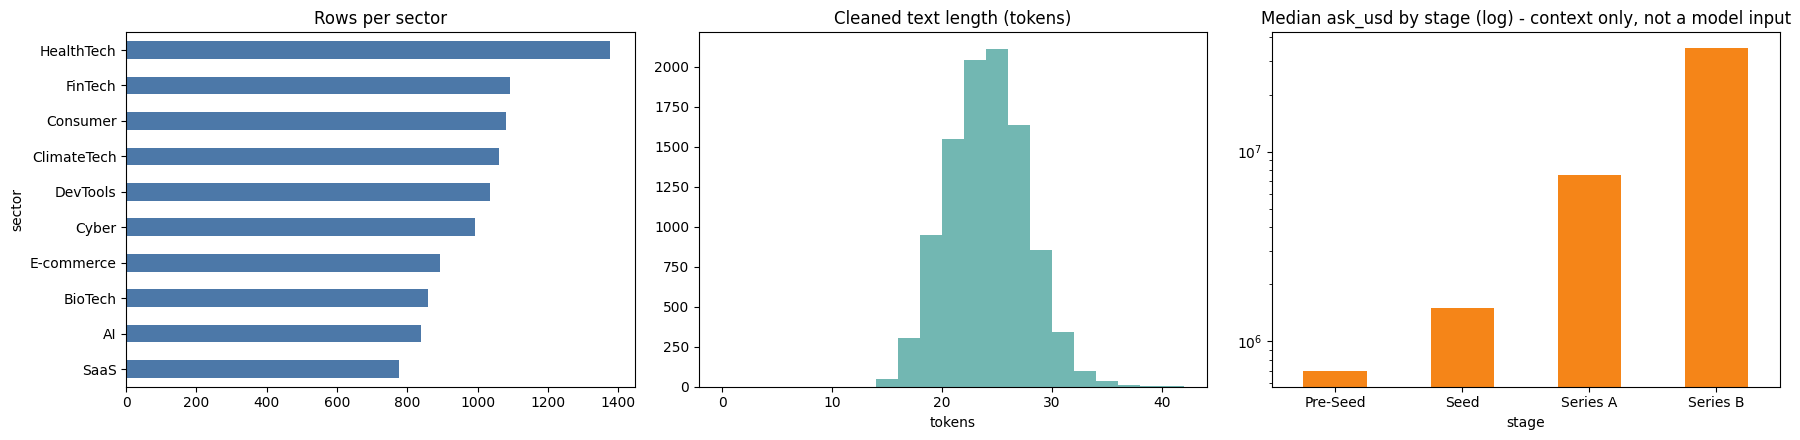

{'count': 10000.0, 'mean': 23.6, 'std': 3.6, 'min': 14.0, '25%': 21.0, '50%': 24.0, '75%': 26.0, 'max': 41.0}


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
df["sector"].value_counts().sort_values().plot.barh(ax=ax[0], color="#4C78A8"); ax[0].set_title("Rows per sector")
ax[1].hist(df["n_tokens"], bins=range(0, int(df["n_tokens"].max()) + 2, 2), color="#72B7B2")
ax[1].set_title("Cleaned text length (tokens)"); ax[1].set_xlabel("tokens")
df.groupby("stage")["ask_usd"].median().reindex(["Pre-Seed", "Seed", "Series A", "Series B"]).plot.bar(ax=ax[2], color="#F58518", rot=0)
ax[2].set_yscale("log"); ax[2].set_title("Median ask_usd by stage (log) - context only, not a model input")
plt.tight_layout(); plt.show()
print(df["n_tokens"].describe().round(1).to_dict())

In [6]:
STOP = set("the a an and or of to in for with on our your you we it is are be by as at from that this their its into more can will".split())
top = {}
for s, g in df.groupby("sector"):
    cnt = collections.Counter(w for toks in g["tokens"] for w in set(toks) if w not in STOP and w not in ("<num>", "[company]"))
    top[s] = cnt
glob_cnt = collections.Counter(w for toks in df["tokens"] for w in set(toks))
rows = []
for s, cnt in top.items():
    n_s = (df["sector"] == s).sum()
    scored = sorted(((c / n_s) / (glob_cnt[w] / len(df)), w, c) for w, c in cnt.items() if c >= 20)[::-1][:8]
    rows.append((s, ", ".join(w for _, w, _ in scored)))
display(pd.DataFrame(rows, columns=["sector", "most distinctive words (lift, count>=20)"]))

,sector,"most distinctive words (lift, count>=20)"
0,AI,"machines, failures, maintenance, equipment, factory, uptime, downtime, predictive"
1,BioTech,"harming, bioremediation, biodegradable, soil, nutrients, farm, biofuels, nutrient"
2,ClimateTech,"building's, building, buildings, efforts, panels, solar, company's, footprints"
3,Consumer,"brand's, appliance, consumer, appliances, meals, skincare, meal, consumers"
4,Cyber,"cybersecurity, threat, cyber, attacks, threats, defense, breaches, world"
5,DevTools,"ci, releases, devtools, devtool, devops, developer, dev, deployment"
6,E-commerce,"fulfillment, commerce's, e, commerce, order, conversions, orders, store's"
7,FinTech,"lenders, investors, fintech, scoring, loan, lending, kyc, approval"
8,HealthTech,"biometric, wearables, vitals, telemedicine, clinics, chronic, patients, doctors"
9,SaaS,"saas, step, chain, supply, unprecedented, b, cost, cloud"


Rows sharing the SAME cleaned text but different business_model: 4

Competitors_count (used only for a later check):
{'count': 9960.0, 'mean': 15.6, 'std': 8.48, 'min': 1.0, '25%': 9.0, '50%': 14.0, '75%': 21.0, 'max': 54.0}


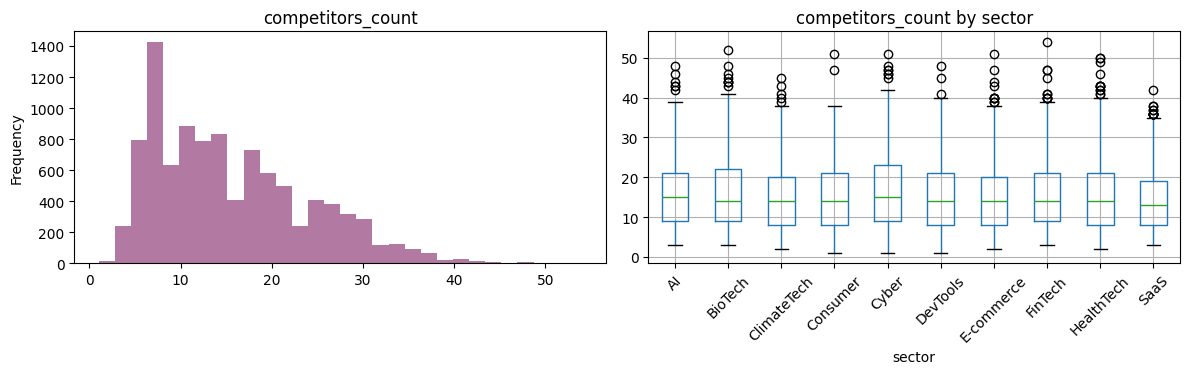

In [7]:
# Business-model and stage vs text: shows why they are not used as targets
tmp = df.copy()
print("Rows sharing the SAME cleaned text but different business_model:",
      int((tmp.groupby("text_clean")["business_model"].nunique() > 1).sum()))
print("\nCompetitors_count (used only for a later check):")
print(df["competitors_count"].describe().round(2).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["competitors_count"].dropna().plot.hist(bins=30, ax=ax[0], color="#B279A2"); ax[0].set_title("competitors_count")
df.boxplot(column="competitors_count", by="sector", ax=ax[1], rot=45); ax[1].set_title("competitors_count by sector"); plt.suptitle("")
plt.tight_layout(); plt.show()

## 6. Leakage-safe split (grouped by identical text)

Many rows share an identical or near-identical pitch. A plain random split would put copies of the same text in train and test and inflate the accuracy. Rows are therefore **grouped by their cleaned text** and the split is stratified by sector (about 71% train / 14% validation / 14% test).

In [8]:
groups = df["text_clean"].str.lower().factorize()[0]
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
folds = [te for _, te in sgkf.split(df, df["sector"], groups)]
idx_test, idx_val = folds[0], folds[1]
idx_train = np.setdiff1d(np.arange(len(df)), np.concatenate([idx_test, idx_val]))

# no text shared between splits
g = lambda ix: set(groups[ix])
assert not (g(idx_train) & g(idx_val)) and not (g(idx_train) & g(idx_test)) and not (g(idx_val) & g(idx_test))
print("No identical text appears in more than one split: OK")

split_tbl = pd.DataFrame({"split": ["train", "val", "test"], "n": [len(idx_train), len(idx_val), len(idx_test)]})
display(split_tbl)
bal = pd.DataFrame({n: df.loc[ix, "sector"].value_counts(normalize=True)
                    for n, ix in [("train", idx_train), ("val", idx_val), ("test", idx_test)]}).round(3)
display(bal)

No identical text appears in more than one split: OK


,split,n
0,train,7144
1,val,1428
2,test,1428


,train,val,test
sector,,,
AI,0.082,0.101,0.075
BioTech,0.084,0.090,0.092
ClimateTech,0.106,0.109,0.104
Consumer,0.106,0.111,0.114
Cyber,0.099,0.104,0.095
DevTools,0.105,0.097,0.102
E-commerce,0.092,0.079,0.085
FinTech,0.109,0.106,0.113
HealthTech,0.138,0.132,0.144


## 7. Text feature engineering

* **Vocabulary** from the *train* split only (`min_freq=2`), index 0 = `<pad>`, 1 = `<unk>`.
* Sequences are truncated at `MAX_LEN` tokens and padded per batch.
* **Word dropout** (10% of tokens replaced by `<unk>`) during training makes the encoder more robust to unseen wording.
* Descriptive linguistic features (length, numbers, vague "buzzword" rate) are explored for insight only. They are not NN inputs.

In [9]:
sector_classes = sorted(df["sector"].unique().tolist())
cls2id = {c: i for i, c in enumerate(sector_classes)}
y_all = df["sector"].map(cls2id).values

cnt = collections.Counter(w for i in idx_train for w in df.at[i, "tokens"])
vocab = {PAD: 0, UNK: 1}
for w, c in cnt.most_common():
    if c >= MIN_FREQ: vocab[w] = len(vocab)
print("Vocabulary size:", len(vocab), "| distinct train tokens:", len(cnt))

def oov_rate(tokens_list):
    tot = unk = 0
    for toks in tokens_list:
        for t in toks:
            if t in (NUM, "[company]"): continue
            tot += 1; unk += t not in vocab
    return unk / max(tot, 1)
print("OOV rate  train: %.3f | val: %.3f | test: %.3f" % tuple(
    oov_rate(df.loc[ix, "tokens"]) for ix in (idx_train, idx_val, idx_test)))

def encode_tokens(tokens, max_len=MAX_LEN):
    ids = [vocab.get(t, 1) for t in tokens[:max_len]]
    return ids or [1]

class TextDS(Dataset):
    def __init__(self, idx): self.x = [encode_tokens(df.at[i, "tokens"]) for i in idx]; self.y = y_all[idx]
    def __len__(self): return len(self.x)
    def __getitem__(self, i): return self.x[i], self.y[i]

def collate(batch):
    L = max(len(x) for x, _ in batch)
    X = torch.zeros(len(batch), L, dtype=torch.long)
    for i, (x, _) in enumerate(batch): X[i, :len(x)] = torch.tensor(x)
    return X, torch.tensor([y for _, y in batch], dtype=torch.long)

ds = {n: TextDS(ix) for n, ix in [("train", idx_train), ("val", idx_val), ("test", idx_test)]}
dl_train = DataLoader(ds["train"], batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate, generator=torch.Generator().manual_seed(SEED))
dl_val   = DataLoader(ds["val"],   batch_size=256, shuffle=False, collate_fn=collate)
dl_test  = DataLoader(ds["test"],  batch_size=256, shuffle=False, collate_fn=collate)
print({k: len(v) for k, v in ds.items()})

Vocabulary size: 1696 | distinct train tokens: 2364
OOV rate  train: 0.004 | val: 0.007 | test: 0.008
{'train': 7144, 'val': 1428, 'test': 1428}


In [10]:
VAGUE_PREVIEW = r"\b(cutting[- ]edge|revolutioni[sz]e\w*|seamless\w*|innovative|ai[- ](?:driven|powered)|state[- ]of[- ]the[- ]art|next[- ]gen\w*|streamline\w*|transform\w*|comprehensive|leverag\w*)\b"
tmp = df.assign(vague=df["text_clean"].str.count(VAGUE_PREVIEW, flags=re.I),
                has_num=df["tokens"].map(lambda t: NUM in t))
display(tmp.groupby("sector")[["n_tokens", "vague", "has_num"]].mean().round(2))

,n_tokens,vague,has_num
sector,,,
AI,23.27,1.89,0.01
BioTech,22.16,1.20,0.02
ClimateTech,23.46,1.31,0.02
Consumer,23.37,1.24,0.03
Cyber,24.15,1.12,0.01
DevTools,23.94,1.79,0.01
E-commerce,25.47,1.87,0.02
FinTech,23.81,1.97,0.04
HealthTech,23.19,1.64,0.00


## 8. Baseline: TF-IDF + Logistic Regression

In [11]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr = tfidf.fit_transform(df.loc[idx_train, "text_clean"])
lr = LogisticRegression(max_iter=3000, C=5.0).fit(Xtr, y_all[idx_train])
base_val  = accuracy_score(y_all[idx_val],  lr.predict(tfidf.transform(df.loc[idx_val,  "text_clean"])))
base_test = accuracy_score(y_all[idx_test], lr.predict(tfidf.transform(df.loc[idx_test, "text_clean"])))
base_f1   = f1_score(y_all[idx_test], lr.predict(tfidf.transform(df.loc[idx_test, "text_clean"])), average="macro")
print(f"Baseline TF-IDF+LR  val acc {base_val:.4f} | test acc {base_test:.4f} | test macro-F1 {base_f1:.4f}")

Baseline TF-IDF+LR  val acc 0.8648 | test acc 0.8452 | test macro-F1 0.8357


## 9. Neural text encoder (PyTorch): BiGRU + attention pooling

In [12]:
SRC_MODEL = r'''
class TextEncoder(nn.Module):
    # Embedding -> BiGRU (packed) -> additive attention pooling -> projection (idea embedding) -> sector head.
    def __init__(self, vocab_size, n_classes, emb_dim=128, hidden=128, embed_dim=128, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.emb_drop = nn.Dropout(dropout)
        self.gru = nn.GRU(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.attn = nn.Linear(2 * hidden, 1)
        self.proj = nn.Sequential(nn.Linear(2 * hidden, embed_dim), nn.LayerNorm(embed_dim), nn.GELU())
        self.drop = nn.Dropout(dropout)
        self.cls = nn.Linear(embed_dim, n_classes)

    def encode(self, x):
        mask = x.ne(0)
        lengths = mask.sum(1).clamp(min=1).cpu()
        e = self.emb_drop(self.emb(x))
        packed = pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False)
        out, _ = self.gru(packed)
        h, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        scores = self.attn(h).squeeze(-1).masked_fill(~mask, -1e9)
        w = torch.softmax(scores, dim=1)
        pooled = (w.unsqueeze(-1) * h).sum(1)
        return self.proj(pooled), w

    def forward(self, x):
        z, w = self.encode(x)
        return self.cls(self.drop(z)), z, w
'''
exec(SRC_MODEL)

set_seed()
model = TextEncoder(len(vocab), len(sector_classes), EMB_DIM, HIDDEN, EMBED_DIM, DROPOUT).to(DEVICE)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

TextEncoder(
  (emb): Embedding(1696, 128, padding_idx=0)
  (emb_drop): Dropout(p=0.3, inplace=False)
  (gru): GRU(128, 128, batch_first=True, bidirectional=True)
  (attn): Linear(in_features=256, out_features=1, bias=True)
  (proj): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    (2): GELU(approximate='none')
  )
  (drop): Dropout(p=0.3, inplace=False)
  (cls): Linear(in_features=128, out_features=10, bias=True)
)
Trainable parameters: 449931


epoch  1 | train loss 1.2317 | val loss 0.6763 | val acc 0.7913
epoch  2 | train loss 0.8587 | val loss 0.5699 | val acc 0.8249
epoch  3 | train loss 0.7783 | val loss 0.5157 | val acc 0.8389
epoch  4 | train loss 0.7356 | val loss 0.4983 | val acc 0.8494
epoch  5 | train loss 0.7043 | val loss 0.4901 | val acc 0.8578
epoch  6 | train loss 0.6682 | val loss 0.4570 | val acc 0.8522
epoch  7 | train loss 0.6372 | val loss 0.4382 | val acc 0.8641
epoch  8 | train loss 0.6225 | val loss 0.4479 | val acc 0.8592
epoch  9 | train loss 0.6054 | val loss 0.4512 | val acc 0.8571
epoch 10 | train loss 0.5948 | val loss 0.4486 | val acc 0.8515
epoch 11 | train loss 0.5604 | val loss 0.4314 | val acc 0.8627
epoch 12 | train loss 0.5421 | val loss 0.4300 | val acc 0.8655
epoch 13 | train loss 0.5285 | val loss 0.4377 | val acc 0.8620
epoch 14 | train loss 0.5196 | val loss 0.4398 | val acc 0.8599
epoch 15 | train loss 0.5239 | val loss 0.4298 | val acc 0.8655
epoch 16 | train loss 0.5086 | val loss 

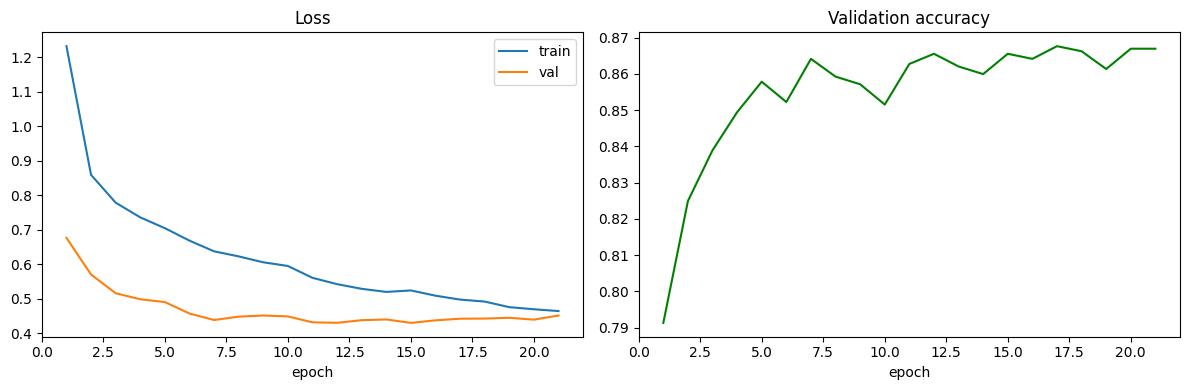

Best validation loss: 0.4298 at epoch 15


In [13]:
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2)
crit = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)

@torch.no_grad()
def run_eval(loader):
    model.eval(); L, P, Y = [], [], []
    for X, y in loader:
        lg, _, _ = model(X.to(DEVICE)); L.append(lg.cpu()); Y.append(y)
    logits, y = torch.cat(L), torch.cat(Y)
    return logits, y, F.cross_entropy(logits, y).item(), (logits.argmax(1) == y).float().mean().item()

hist, best_val, best_state, bad = [], float("inf"), None, 0
for ep in range(1, MAX_EPOCHS + 1):
    model.train(); tot = n = 0
    for X, y in dl_train:
        X, y = X.to(DEVICE), y.to(DEVICE)
        drop = (torch.rand_like(X, dtype=torch.float) < WORD_DROPOUT) & X.ne(0)
        X = X.masked_fill(drop, 1)                      # word dropout -> <unk>
        loss = crit(model(X)[0], y)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        tot += loss.item() * len(y); n += len(y)
    _, _, vl, va = run_eval(dl_val); sched.step(vl)
    hist.append({"epoch": ep, "train_loss": tot / n, "val_loss": vl, "val_acc": va, "lr": opt.param_groups[0]["lr"]})
    print(f"epoch {ep:2d} | train loss {tot/n:.4f} | val loss {vl:.4f} | val acc {va:.4f}")
    if vl < best_val - 1e-4:
        best_val, bad = vl, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        bad += 1
        if bad >= PATIENCE: print("Early stopping."); break

model.load_state_dict(best_state); model.to(DEVICE)
hist = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist["epoch"], hist["train_loss"], label="train"); ax[0].plot(hist["epoch"], hist["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
ax[1].plot(hist["epoch"], hist["val_acc"], color="green"); ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()
print("Best validation loss:", round(best_val, 4), "at epoch", int(hist.loc[hist["val_loss"].idxmin(), "epoch"]))

## 10. Probability calibration (temperature scaling) and final test evaluation

The NN's sector probabilities are used downstream as a confidence signal, so they are calibrated with a single **temperature** fitted on the validation split. The test split is used once, for the final numbers.

In [14]:
val_logits, val_y, _, _ = run_eval(dl_val)
logT = torch.zeros(1, requires_grad=True)
lbfgs = torch.optim.LBFGS([logT], lr=0.1, max_iter=200)
def closure():
    lbfgs.zero_grad(); loss = F.cross_entropy(val_logits / logT.exp(), val_y); loss.backward(); return loss
lbfgs.step(closure)
TEMPERATURE = float(logT.exp().item())
print("Fitted temperature:", round(TEMPERATURE, 3))

def ece_multiclass(probs, y, bins=10):
    conf, pred = probs.max(1); acc = (pred == y).float(); e = 0.0
    edges = torch.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.float().mean().item() * abs(acc[m].mean().item() - conf[m].mean().item())
    return e

test_logits, test_y, test_loss, test_acc = run_eval(dl_test)
p_raw, p_cal = F.softmax(test_logits, 1), F.softmax(test_logits / TEMPERATURE, 1)
pred = p_cal.argmax(1).numpy(); yt = test_y.numpy()

res = pd.DataFrame({
    "accuracy":  [accuracy_score(yt, pred), base_test],
    "macro_F1":  [f1_score(yt, pred, average="macro"), base_f1],
    "NLL":       [F.nll_loss(torch.log(p_cal + 1e-9), test_y).item(), np.nan],
    "ECE":       [ece_multiclass(p_cal, test_y), np.nan],
}, index=["PyTorch BiGRU-attention (calibrated)", "TF-IDF + LogReg baseline"]).round(4)
display(res)
print("Uncalibrated NN: NLL %.4f | ECE %.4f" % (F.nll_loss(torch.log(p_raw + 1e-9), test_y).item(), ece_multiclass(p_raw, test_y)))

# bootstrap 95% CI for accuracy
rng = np.random.default_rng(SEED)
accs = [accuracy_score(yt[i], pred[i]) for i in (rng.integers(0, len(yt), len(yt)) for _ in range(1000))]
print("Test accuracy 95%% CI: %.3f - %.3f" % (np.percentile(accs, 2.5), np.percentile(accs, 97.5)))
print()
print(classification_report(yt, pred, target_names=sector_classes, digits=3))

Fitted temperature: 1.005


,accuracy,macro_F1,NLL,ECE
PyTorch BiGRU-attention (calibrated),0.8613,0.8518,0.4675,0.0235
TF-IDF + LogReg baseline,0.8452,0.8357,NaN,NaN


Uncalibrated NN: NLL 0.4676 | ECE 0.0242
Test accuracy 95% CI: 0.843 - 0.878

              precision    recall  f1-score   support

          AI      0.763     0.692     0.725       107
     BioTech      0.917     0.917     0.917       132
 ClimateTech      0.764     0.811     0.787       148
    Consumer      0.753     0.804     0.777       163
       Cyber      0.963     0.970     0.967       135
    DevTools      0.925     0.842     0.882       146
  E-commerce      0.942     0.934     0.938       121
     FinTech      0.892     0.919     0.905       161
  HealthTech      0.952     0.961     0.957       206
        SaaS      0.676     0.651     0.664       109

    accuracy                          0.861      1428
   macro avg      0.855     0.850     0.852      1428
weighted avg      0.862     0.861     0.861      1428



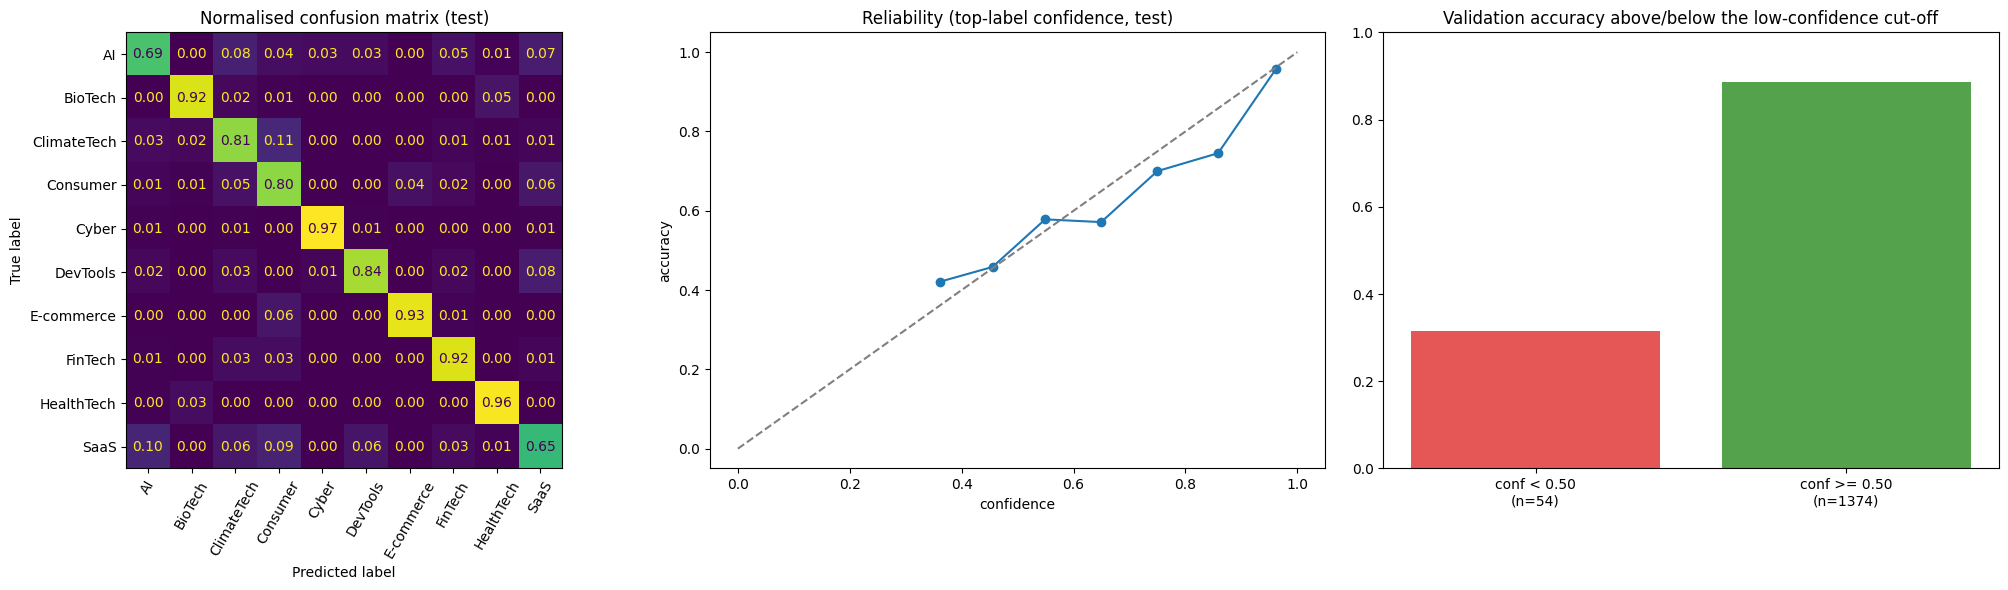

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(21, 6))
ConfusionMatrixDisplay(confusion_matrix(yt, pred, normalize="true"), display_labels=sector_classes).plot(
    ax=ax[0], xticks_rotation=60, colorbar=False, values_format=".2f")
ax[0].set_title("Normalised confusion matrix (test)")

conf = p_cal.max(1).values.numpy(); correct = (pred == yt)
bins = np.linspace(0, 1, 11); mids, accb = [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    m = (conf > lo) & (conf <= hi)
    if m.sum() >= 5: mids.append(conf[m].mean()); accb.append(correct[m].mean())
ax[1].plot(mids, accb, marker="o"); ax[1].plot([0, 1], [0, 1], "--", c="gray")
ax[1].set_title("Reliability (top-label confidence, test)"); ax[1].set_xlabel("confidence"); ax[1].set_ylabel("accuracy")

vc = F.softmax(val_logits / TEMPERATURE, 1).max(1).values.numpy(); vcorrect = (F.softmax(val_logits, 1).argmax(1) == val_y).numpy()
lowm = vc < LOW_CONF
ax[2].bar(["conf < %.2f\n(n=%d)" % (LOW_CONF, lowm.sum()), "conf >= %.2f\n(n=%d)" % (LOW_CONF, (~lowm).sum())],
          [vcorrect[lowm].mean() if lowm.any() else 0, vcorrect[~lowm].mean()], color=["#E45756", "#54A24B"])
ax[2].set_ylim(0, 1); ax[2].set_title("Validation accuracy above/below the low-confidence cut-off")
plt.tight_layout(); plt.show()

## 11. Embedding analysis

1. **t-SNE** of idea embeddings (validation + test) coloured by sector.
2. **Similarity signal check:** for each held-out startup, the mean cosine similarity to its 10 nearest *training* neighbours is a text "crowdedness" measure. It is compared with the (independent) `competitors_count` column. If it does not correlate, it must **not** be used as evidence about competition, and the inference code states that.

Embedding matrices: (7144, 128) (1428, 128) (1428, 128)


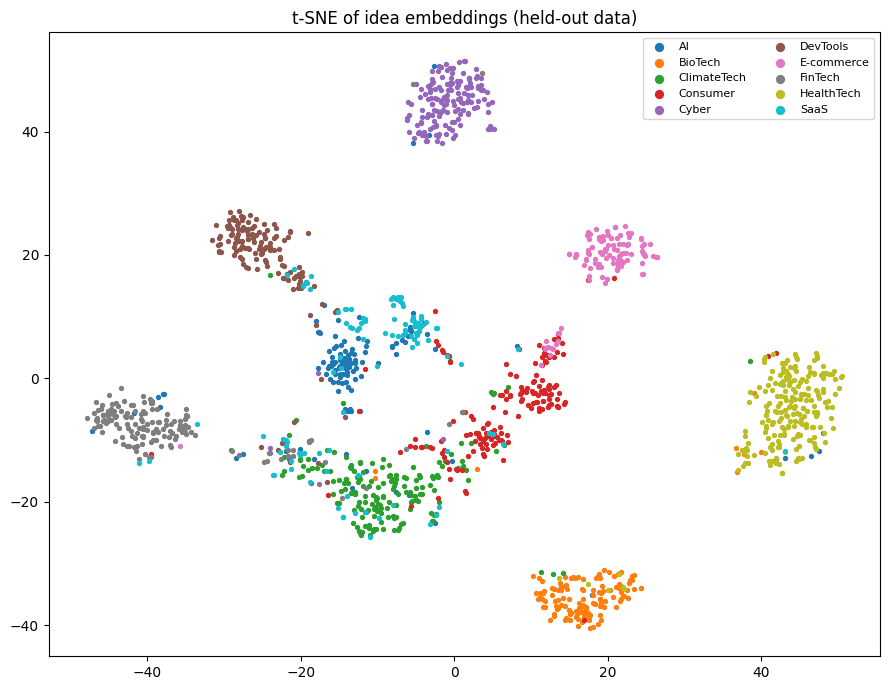

In [16]:
@torch.no_grad()
def embed_loader(loader):
    model.eval(); Z = []
    for X, _ in loader: Z.append(F.normalize(model.encode(X.to(DEVICE))[0], dim=1).cpu())
    return torch.cat(Z)

dl_train_eval = DataLoader(ds["train"], batch_size=256, shuffle=False, collate_fn=collate)
Z_train, Z_val, Z_test = embed_loader(dl_train_eval), embed_loader(dl_val), embed_loader(dl_test)
print("Embedding matrices:", tuple(Z_train.shape), tuple(Z_val.shape), tuple(Z_test.shape))

Zv = torch.cat([Z_val, Z_test]).numpy(); sv = np.array(sector_classes)[np.concatenate([y_all[idx_val], y_all[idx_test]])]
sel = np.random.default_rng(SEED).choice(len(Zv), size=min(1500, len(Zv)), replace=False)
emb2d = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Zv[sel])
plt.figure(figsize=(9, 7))
for s in sector_classes:
    m = sv[sel] == s; plt.scatter(emb2d[m, 0], emb2d[m, 1], s=8, label=s)
plt.legend(markerscale=2, fontsize=8, ncol=2); plt.title("t-SNE of idea embeddings (held-out data)"); plt.tight_layout(); plt.show()

Spearman(crowdedness, competitors_count) over held-out rows: rho=0.011, p=0.542, n=2844
Mean within-sector rho: 0.013

Similarity signal validated against competitors_count: False
-> It will be shown only as 'similar startups for reference'. It will NOT be interpreted as competition.


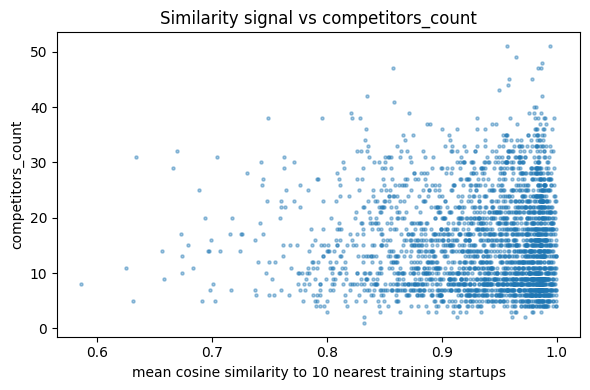

In [17]:
def crowdedness(Zq, k=10):
    sims = Zq @ Z_train.T
    return sims.topk(k, dim=1).values.mean(1).numpy()

crowd_val, crowd_test = crowdedness(Z_val), crowdedness(Z_test)
heldout_idx = np.concatenate([idx_val, idx_test]); crowd_held = np.concatenate([crowd_val, crowd_test])
cc = df.loc[heldout_idx, "competitors_count"].values; ok = ~np.isnan(cc)
rho, pval = spearmanr(crowd_held[ok], cc[ok])
print(f"Spearman(crowdedness, competitors_count) over held-out rows: rho={rho:.3f}, p={pval:.3g}, n={ok.sum()}")

# within-sector (controls for sector effects)
w_rhos = []
for s in sector_classes:
    m = ok & (df.loc[heldout_idx, "sector"].values == s)
    if m.sum() > 30: w_rhos.append(spearmanr(crowd_held[m], cc[m])[0])
print("Mean within-sector rho:", round(float(np.mean(w_rhos)), 3))

SIMILARITY_VALIDATED = bool(abs(rho) >= 0.10 and pval < 0.01)
print("\nSimilarity signal validated against competitors_count:", SIMILARITY_VALIDATED)
if not SIMILARITY_VALIDATED:
    print("-> It will be shown only as 'similar startups for reference'. It will NOT be interpreted as competition.")
CROWD_REF = np.sort(crowd_val).astype(float).tolist()    # out-of-sample reference distribution (validation split)

plt.figure(figsize=(6, 4)); plt.scatter(crowd_held[ok], cc[ok], s=5, alpha=.4)
plt.xlabel("mean cosine similarity to 10 nearest training startups"); plt.ylabel("competitors_count"); plt.title("Similarity signal vs competitors_count")
plt.tight_layout(); plt.show()

## 12. Rule-based aspect findings (transparent, **not validated**, no scores)

For each aspect in the project plan the engine looks for explicit textual cues, quotes the supporting sentences, and lists what is missing.

* Status values: `evidence_found`, `partial` (only generic wording), `not_stated`.
* **"Not stated" means the text does not say it, not that the aspect is weak.** Optional information is never treated as a weakness.
* Vague buzzwords are flagged separately.
* Feasibility is reported as *risk signals detected* (regulatory, clinical, manufacturing, ...). "None detected" does not mean no risk.
* The lexicons are explicit and editable below. They have **not** been validated against labelled data. Section 12 only tests that the rules behave as written.

In [18]:
SRC_RULES = r'''
CUSTOMER_NOUNS = (r"restaurants?|owners?|operators?|shops?|stores?|retailers?|merchants?|sellers?|shoppers?|consumers?|families|parents|"
    r"patients?|doctors?|clinicians?|nurses?|clinics?|hospitals?|pharmacies|teams?|managers?|companies|businesses|enterprises?|smbs?|smes?|"
    r"startups?|developers?|engineers?|devops|ciso|cto|cfo|banks?|lenders?|investors?|traders?|insurers?|farmers?|growers?|schools?|"
    r"teachers?|students?|universities|creators?|freelancers?|artists?|gamers?|homeowners?|renters?|drivers?|fleets?|manufacturers?|"
    r"factories|warehouses?|suppliers?|utilities|municipalities|governments?|seniors?|elderly|athletes|travell?ers?|employees|recruiters?|"
    r"lawyers?|accountants?|brands?|agencies|users?|customers?|clients?|people|everyone|organi[sz]ations?")
GENERIC_CUSTOMER = {"companies", "businesses", "consumers", "consumer", "teams", "team", "users", "user", "customers", "customer",
                    "people", "everyone", "enterprises", "enterprise", "organizations", "organisations", "brands", "clients", "client"}

VAGUE_TERMS = (r"cutting[- ]edge|revolutioni[sz]\w*|seamless\w*|innovative|disruptive|disrupt\w*|game[- ]chang\w*|state[- ]of[- ]the[- ]art|"
               r"next[- ]gen\w*|ai[- ](?:driven|powered)|synerg\w*|leverag\w*|holistic|world[- ]class|best[- ]in[- ]class|"
               r"streamline\w*|transform\w*|comprehensive|end[- ]to[- ]end|robust|scalable|smart")

ASPECTS = [
 dict(key="problem_clarity", label="Problem clarity", kind="evidence",
      patterns=[r"\b(problem|pain points?|struggl\w*|challenges?|frustrat\w*|lack\w*|unable|inefficien\w*|costly|expensive|slow|manual(?:ly)?|"
                r"wast\w*|error[- ]prone|difficult\w*|no way to|too (?:hard|slow|expensive|costly)|lose|loses|losing|fail\w*|risk\w*|delays?)\b"],
      ask="What specific problem does your customer have today, how often does it occur, and how do they cope with it now?"),
 dict(key="target_customer_clarity", label="Target customer clarity", kind="evidence",
      patterns=[r"\b(?:" + CUSTOMER_NOUNS + r")\b"], generic=GENERIC_CUSTOMER,
      ask="Who exactly is the first customer segment (role, company size or demographic, region)?"),
 dict(key="solution_specificity", label="Solution specificity", kind="evidence",
      patterns=[r"\b(machine learning|computer vision|nlp|llm|algorithms?|api|apis|sensors?|blockchain|encryption|mobile app|web app|dashboard|"
                r"integrat\w*|wearables?|iot|devices?|chatbot|marketplace|plugin|browser extension|platform that|software that|app that|"
                r"uses|using|via|through|by (?:\w+ing))\b", r"\d"],
      ask="How exactly does the product solve the problem (core mechanism, key features, what the user does step by step)?"),
 dict(key="market_need_validation", label="Market need / validation evidence", kind="evidence",
      patterns=[r"\b(interview\w*|surveys?|survey(?:ed)?|waitlist|wait list|pilot\w*|loi|letters? of intent|pre-?orders?|beta (?:users?|testers?)|"
                r"early adopters?|design partners?|validat\w*|customer discovery|signed|committed|research shows)\b"],
      ask="What evidence do you have that the need exists (interviews, surveys, waitlist, pilots, letters of intent)?"),
 dict(key="differentiation", label="Differentiation from competitors", kind="evidence",
      patterns=[r"\b(unlike|compared (?:to|with)|versus|vs\.?|patent\w*|proprietary|moat|differentiat\w*|competitors?|alternatives?|"
                r"better than|faster than|cheaper than|instead of|incumbents?)\b", r"\b\d+\s?x\b"],
      ask="Who are the main competitors or substitutes, and what do you do that they cannot or do not?"),
 dict(key="business_model_clarity", label="Business model clarity", kind="evidence",
      patterns=[r"\b(subscriptions?|per seat|per user|per month|usage[- ]based|pay[- ]per|commissions?|take rate|transaction fees?|licen[sc]\w*|"
                r"freemium|saas|pricing|priced?|revenue (?:model|streams?)|margins?|mrr|arr|recurring|b2b2c|b2b|b2c|marketplace)\b",
                r"[$€£]\s?\d"],
      ask="How do you make money (who pays, how much, how often) and what is the expected margin?"),
 dict(key="feasibility_challenges", label="Feasibility / execution challenges", kind="risk",
      patterns=[r"\b(fda|clinical (?:trials?|validation)|regulat\w*|compliance|hipaa|gdpr|certif\w*|medical devices?|manufactur\w*|prototype|"
                r"kyc|aml|banking licen[sc]e|r&d|deep tech|safety[- ]critical|patient data|sensitive data|security audit)\b"],
      ask="Which technical, regulatory or operational hurdles must be cleared before launch, and what is the plan and budget for each?"),
 dict(key="customer_demand_evidence", label="Evidence of customer demand", kind="evidence",
      patterns=[r"\b\d[\d,\.]*\s?[km]?\+?\s*(?:paying |active |monthly |beta |pilot )?(?:customers?|users?|clients?|subscribers?|sign-?ups?|downloads?|"
                r"pilots?|partners?|stores?|clinics?|hospitals?|orders?)\b",
                r"\b(revenue|paying customers?|retention|churn|repeat (?:customers?|purchases?)|waitlist|growing \d+%|\d+%\s*(?:growth|mom))\b"],
      ask="What traction shows people want this (paying customers, active users, repeat usage, revenue, waitlist size)?"),
]
for _a in ASPECTS:
    _a["rx"] = [re.compile(p, re.I) for p in _a["patterns"]]
_VAGUE_RX = re.compile(r"\b(?:" + VAGUE_TERMS + r")\b", re.I)

def _find_evidence(text, rxs, max_snips=3):
    snips, matched = [], []
    for s in split_sentences(text):
        hits = []
        for rx in rxs:
            hits += [m.group(0) for m in rx.finditer(s)]
        if hits:
            snips.append({"text": s[:240], "matched": sorted(set(h.lower() for h in hits))[:6]})
            matched += [h.lower() for h in hits]
        if len(snips) >= max_snips: break
    return snips, matched

def analyze_aspects(text):
    out = []
    for a in ASPECTS:
        snips, matched = _find_evidence(text, a["rx"])
        if a["kind"] == "risk":
            status = "risk_signals_found" if snips else "none_detected"
            note = ("Possible execution hurdles are mentioned; check each has a plan." if snips else
                    "No hurdles were detected in the text. This does not mean there are none.")
        else:
            status = "evidence_found" if snips else "not_stated"
            note = "" if snips else "Not stated in the provided text. This does not mean the aspect is weak; it cannot be assessed."
            if snips and a.get("generic") and all(m in a["generic"] for m in matched):
                status, note = "partial", "Only generic wording was found (" + ", ".join(sorted(set(matched))[:4]) + "); no specific segment is named."
        out.append({"key": a["key"], "aspect": a["label"], "status": status, "evidence": snips, "note": note, "question": a["ask"]})
    vague = sorted(set(m.group(0).lower() for m in _VAGUE_RX.finditer(text)))
    return out, vague
'''
exec(SRC_RULES)

# ---- sanity tests: do the rules behave as written? (NOT a validation of their predictive value) ----
t_good = ("Small restaurants lose 30% of their food to spoilage because they track inventory by hand. We sell a $99/month subscription app "
          "that uses computer vision on a phone camera to log stock. We interviewed 40 owners and have 12 paying customers; unlike Toast, we need no extra devices.")
t_vague = "Our cutting-edge AI-driven platform will revolutionize the industry with seamless, innovative solutions."
r_good, v_good = analyze_aspects(t_good); r_vague, v_vague = analyze_aspects(t_vague)
st_good  = {r["key"]: r["status"] for r in r_good};  st_vague = {r["key"]: r["status"] for r in r_vague}
assert st_good["problem_clarity"] == "evidence_found" and st_good["target_customer_clarity"] == "evidence_found"
assert st_good["market_need_validation"] == "evidence_found" and st_good["differentiation"] == "evidence_found"
assert st_good["business_model_clarity"] == "evidence_found" and st_good["customer_demand_evidence"] == "evidence_found"
assert st_vague["target_customer_clarity"] == "not_stated" and st_vague["market_need_validation"] == "not_stated"
assert st_vague["business_model_clarity"] == "not_stated" and st_vague["customer_demand_evidence"] == "not_stated"
assert len(v_vague) >= 3 and len(v_good) == 0
assert analyze_aspects("Tools for companies.")[0][1]["status"] == "partial"
print("Rule sanity tests passed.")
display(pd.DataFrame([{"aspect": r["aspect"], "good_example": st_good[r["key"]], "vague_example": st_vague[r["key"]]} for r in r_good]))
print("Vague terms found in vague example:", v_vague)

Rule sanity tests passed.


,aspect,good_example,vague_example
0,Problem clarity,evidence_found,not_stated
1,Target customer clarity,evidence_found,not_stated
2,Solution specificity,evidence_found,not_stated
3,Market need / validation evidence,evidence_found,not_stated
4,Differentiation from competitors,evidence_found,not_stated
5,Business model clarity,evidence_found,not_stated
6,Feasibility / execution challenges,none_detected,none_detected
7,Evidence of customer demand,evidence_found,not_stated


Vague terms found in vague example: ['ai-driven', 'cutting-edge', 'innovative', 'revolutionize', 'seamless']


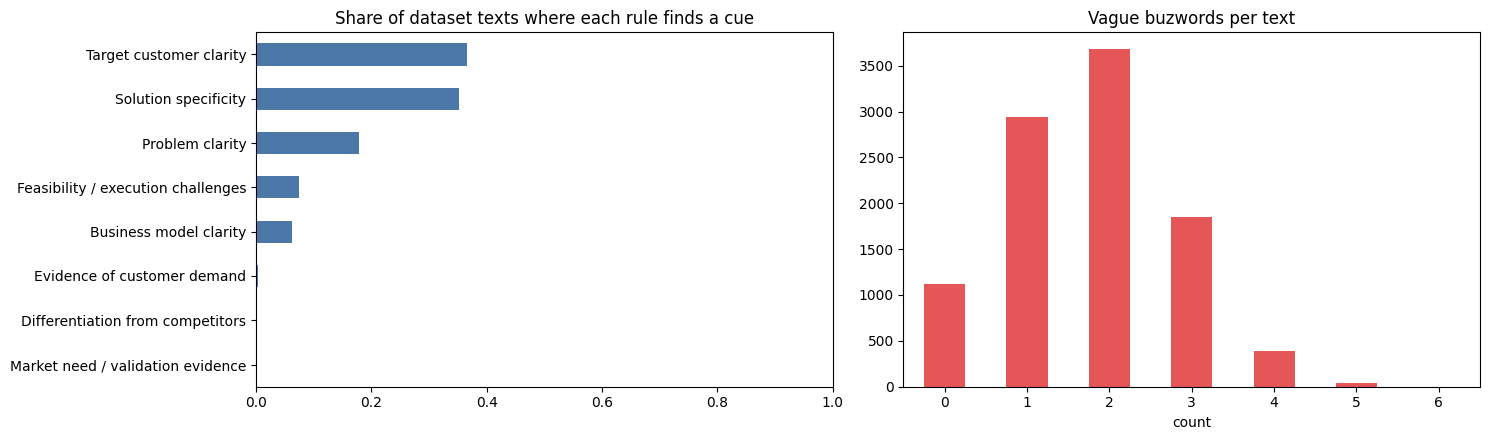

Share of texts with at least one vague term: 88.8%


In [19]:
# Descriptive prevalence of the rule cues in this dataset (short pitches => most cues absent, which is expected)
prev = {}
for a in ASPECTS:
    prev[a["label"]] = df["text_clean"].map(lambda t: any(rx.search(t) for rx in a["rx"])).mean()
vag = df["text_clean"].map(lambda t: len(_VAGUE_RX.findall(t)))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
pd.Series(prev).sort_values().plot.barh(ax=ax[0], color="#4C78A8"); ax[0].set_xlim(0, 1)
ax[0].set_title("Share of dataset texts where each rule finds a cue")
vag.value_counts().sort_index().plot.bar(ax=ax[1], color="#E45756", rot=0); ax[1].set_title("Vague buzwords per text"); ax[1].set_xlabel("count")
plt.tight_layout(); plt.show()
print("Share of texts with at least one vague term: %.1f%%" % (100 * (vag > 0).mean()))

## 13. Inference module: NN + rules -> structured Model C output

`evaluate_idea()` returns the aspect-wise findings, strengths, gaps, supporting text, missing-information questions, the sector-consistency check, similar startups and warnings, in a structure the report builder (and then the LLM) can consume. Everything is written to `model_c_inference.py`.

In [20]:
SRC_INFER = r'''
def load_bundle(path, device="cpu"):
    ck = torch.load(path, map_location=device, weights_only=True)
    cfg = ck["config"]
    model = TextEncoder(len(ck["vocab"]), len(ck["classes"]), cfg["emb_dim"], cfg["hidden"], cfg["embed_dim"], cfg["dropout"])
    model.load_state_dict(ck["state_dict"]); model.to(device).eval()
    ck["model"] = model; ck["device"] = device
    return ck

def _ids(vocab, token_lists, max_len):
    seqs = [[vocab.get(t, 1) for t in toks[:max_len]] or [1] for toks in token_lists]
    X = torch.zeros(len(seqs), max(len(s) for s in seqs), dtype=torch.long)
    for i, s in enumerate(seqs):
        X[i, :len(s)] = torch.tensor(s)
    return X

@torch.no_grad()
def nn_analysis(bundle, text, top_sim=5):
    cfg, vocab, classes = bundle["config"], bundle["vocab"], bundle["classes"]
    chunks = chunk_text(text, cfg["chunk_tokens"])
    toks = [tokenize(c) for c in chunks]
    X = _ids(vocab, toks, cfg["max_len"]).to(bundle["device"])
    logits, z, w = bundle["model"](X)
    wt = torch.tensor([max(len(t), 1) for t in toks], dtype=torch.float, device=logits.device); wt = wt / wt.sum()
    logit = (logits * wt[:, None]).sum(0) / bundle["temperature"]
    probs = torch.softmax(logit, 0).cpu()
    emb = F.normalize((z * wt[:, None]).sum(0), dim=0).cpu()
    sims = bundle["train_emb"] @ emb
    top = sims.topk(top_sim)
    ks = sims.topk(10).values.mean().item()
    pct = float(np.searchsorted(np.array(bundle["crowd_ref"]), ks) / len(bundle["crowd_ref"]) * 100)
    # attention: which words drove the representation
    att = {}
    for ti, t in enumerate(toks):
        for pos, tok in enumerate(t[:cfg["max_len"]]):
            if tok in (NUM, "[company]") or len(tok) < 3: continue
            att[tok] = max(att.get(tok, 0.0), float(w[ti, pos]))
    key_terms = [k for k, _ in sorted(att.items(), key=lambda kv: -kv[1])[:8]]
    all_tok = [t for ts in toks for t in ts if t not in (NUM, "[company]")]
    oov = sum(t not in vocab for t in all_tok) / max(len(all_tok), 1)
    order = probs.argsort(descending=True)[:3].tolist()
    return {
        "top_sectors": [{"sector": classes[i], "probability": round(float(probs[i]), 3)} for i in order],
        "confidence": round(float(probs[order[0]]), 3),
        "oov_rate": round(float(oov), 3),
        "n_chunks": len(chunks),
        "key_terms": key_terms,
        "similar_startups": [{"similarity": round(float(s), 3), "sector": bundle["train_sector"][int(i)], "text": bundle["train_text"][int(i)]}
                             for s, i in zip(top.values, top.indices)],
        "mean_top10_similarity": round(ks, 3),
        "similarity_percentile_vs_reference": round(pct, 1),
    }

_FIELD_LABELS = {"problem": "Problem", "target_customer": "Target customer", "business_model": "Business model",
                 "validation_evidence": "Validation", "competitors": "Competitors", "traction": "Traction"}

def evaluate_idea(bundle, idea_text, declared_sector=None, extra=None):
    # idea_text: free-text idea description. extra: optional dict with any of
    # problem, target_customer, business_model, validation_evidence, competitors, traction (empty/None = not provided).
    extra = {k: v for k, v in (extra or {}).items() if v and str(v).strip()}
    own = clean_text(idea_text)
    full = " ".join([own] + [f"{_FIELD_LABELS.get(k, k)}: {str(v).strip().rstrip('.')}." for k, v in extra.items()])
    meta = bundle["metadata"]
    warnings = []
    n_words = len(tokenize(own))
    if n_words < MIN_WORDS_WARN:
        warnings.append(f"The idea description is very short ({n_words} words); findings will be mostly 'not stated'.")
    nn = nn_analysis(bundle, own if own else full)
    if nn["oov_rate"] > OOV_WARN:
        warnings.append(f"{nn['oov_rate']:.0%} of the words were not seen in training. The NN is trained on short, templated pitches, so its outputs are unreliable here.")
    if nn["confidence"] < LOW_CONF:
        warnings.append("The sector prediction has low confidence; treat the NN outputs as weak.")
    if n_words > 3 * meta["config"]["chunk_tokens"]:
        warnings.append("The description is much longer than the training texts; it was split into chunks and averaged.")

    sector_check = {"declared_sector": declared_sector, "predicted_top_sectors": nn["top_sectors"], "consistent": None, "note": ""}
    if declared_sector:
        if declared_sector in bundle["classes"]:
            top1 = nn["top_sectors"][0]
            in_top2 = declared_sector in [s["sector"] for s in nn["top_sectors"][:2]]
            if in_top2:
                sector_check["consistent"] = True
                sector_check["note"] = "The description is consistent with the declared sector."
            elif nn["confidence"] >= 0.7:
                sector_check["consistent"] = False
                sector_check["note"] = (f"The description reads more like '{top1['sector']}' ({top1['probability']:.0%}) than the declared "
                                        f"'{declared_sector}'; check the industry selection or add detail.")
            else:
                sector_check["consistent"] = None
                sector_check["note"] = "The NN is not confident enough to confirm or contradict the declared sector."
        else:
            sector_check["note"] = "Declared sector is not one of the sectors the NN was trained on, so the consistency check was skipped."

    aspects, vague = analyze_aspects(full)
    strengths, gaps, missing = [], [], []
    for a in aspects:
        if a["status"] == "evidence_found":
            strengths.append({"aspect": a["aspect"], "supporting_text": [e["text"] for e in a["evidence"]]})
        elif a["status"] in ("not_stated", "partial"):
            gaps.append({"aspect": a["aspect"], "detail": a["note"]})
            missing.append({"aspect": a["aspect"], "question": a["question"]})
        elif a["status"] == "risk_signals_found":
            gaps.append({"aspect": a["aspect"], "detail": a["note"], "supporting_text": [e["text"] for e in a["evidence"]]})
    if vague:
        gaps.append({"aspect": "Vague language", "detail": "Buzzwords without concrete detail: " + ", ".join(vague) + ". Replace with specifics (who, what, how much)."})

    similar_note = ("Nearest startups in the training corpus by text similarity, for reference only. "
                    + ("Similarity density was validated against competitors_count, but remains an exploratory signal."
                       if meta["similarity_signal_validated"] else
                       "Similarity density did NOT correlate with competitors_count in validation, so it must not be read as competition evidence."))
    return {
        "provided_fields": sorted(extra.keys()),
        "sector_check": sector_check,
        "nn_confidence": nn["confidence"],
        "key_terms_attended_by_nn": nn["key_terms"],
        "aspect_findings": aspects,
        "strengths": strengths,
        "potential_weaknesses_and_gaps": gaps,
        "missing_information_questions": missing,
        "vague_terms": vague,
        "similar_startups": nn["similar_startups"],
        "similarity_note": similar_note,
        "warnings": warnings,
        "validation_status": {
            "neural_sector_encoder": "validated on held-out grouped split (see metadata test_metrics)",
            "aspect_findings": "rule-based, NOT validated against labelled data; no scores are produced",
            "similarity_signal": "validated" if meta["similarity_signal_validated"] else "not validated",
        },
        "limitations": ["Text alone cannot establish that market demand exists.",
                        "'Not stated' means the text does not say it; it is not evidence the aspect is weak.",
                        "Training texts were short, templated pitches; real descriptions are out-of-distribution for the NN."],
    }
'''
exec(SRC_INFER)

MODULE_HEADER = '''# Model C inference module (auto-generated by the training notebook). Usage:
#   import model_c_inference as mc
#   bundle = mc.load_bundle("model_c_encoder.pt")
#   report = mc.evaluate_idea(bundle, idea_text, declared_sector="FinTech", extra={...})
import re, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

MIN_WORDS_WARN, OOV_WARN, LOW_CONF = %d, %.2f, %.2f
''' % (MIN_WORDS_WARN, OOV_WARN, LOW_CONF)
with open(os.path.join(OUTPUT_DIR, "model_c_inference.py"), "w") as f:
    f.write(MODULE_HEADER + SRC_TEXT + SRC_MODEL + SRC_RULES + SRC_INFER)
print("Wrote", os.path.join(OUTPUT_DIR, "model_c_inference.py"))

Wrote /kaggle/working/model_c_inference.py


## 14. Save the final model bundle

In [21]:
test_metrics = {"accuracy": round(float(accuracy_score(yt, pred)), 4),
                "macro_f1": round(float(f1_score(yt, pred, average="macro")), 4),
                "nll_calibrated": round(float(F.nll_loss(torch.log(p_cal + 1e-9), test_y).item()), 4),
                "ece_calibrated": round(float(ece_multiclass(p_cal, test_y)), 4),
                "accuracy_95ci": [round(float(np.percentile(accs, 2.5)), 3), round(float(np.percentile(accs, 97.5)), 3)],
                "baseline_tfidf_lr_accuracy": round(float(base_test), 4)}

metadata = {
    "model_name": "Model C - PyTorch BiGRU+attention text encoder (sector-supervised) + rule-based aspect findings",
    "purpose": "Extract text signals from a startup idea description. Produces NO predictive quality score.",
    "data_provenance": f"{os.path.basename(DATA_PATH)}: {len(df)} startup pitch records (short, templated, apparently synthetic); no outcome or quality labels.",
    "supervised_target": "sector (10 classes). business_model and stage deliberately not used (near-chance predictability from text).",
    "inputs_used": ["pitch", "elevator_speech (company name masked, boilerplate removed)"],
    "inputs_excluded": ["ask_usd", "ARR", "BURN_RATE", "VALUE", "stage", "business_model", "keywords", "text_profile", "competitors_count (check only)"],
    "split": {"method": "StratifiedGroupKFold grouped by identical cleaned text", "n_train": int(len(idx_train)), "n_val": int(len(idx_val)), "n_test": int(len(idx_test))},
    "config": {"max_len": MAX_LEN, "chunk_tokens": CHUNK_TOKENS, "emb_dim": EMB_DIM, "hidden": HIDDEN, "embed_dim": EMBED_DIM, "dropout": DROPOUT},
    "temperature": round(TEMPERATURE, 4),
    "test_metrics": test_metrics,
    "similarity_signal_validated": SIMILARITY_VALIDATED,
    "similarity_vs_competitors_count": {"spearman_rho": round(float(rho), 4), "p_value": float(pval), "n": int(ok.sum())},
    "oov_rate": {"train": round(oov_rate(df.loc[idx_train, "tokens"]), 3), "val": round(oov_rate(df.loc[idx_val, "tokens"]), 3),
                 "test": round(oov_rate(df.loc[idx_test, "tokens"]), 3)},
    "rule_engine": {"aspects": [a["label"] for a in ASPECTS], "validated": False,
                    "note": "Transparent regex/lexicon rules; only sanity-tested that they behave as written."},
    "limitations": [
        "No outcome or aspect-quality labels exist in the training data, so no predictive idea-quality score is produced.",
        "Training texts are short (about 14 words), templated and apparently synthetic; real founder descriptions are out-of-distribution.",
        "Aspect findings are unvalidated rules; 'not stated' is not evidence of weakness.",
        "Text alone cannot establish market demand.",
        "Sector labels come from the dataset and cover only 10 sectors.",
        "Similarity retrieval uses only training-corpus startups and is not a competitor analysis.",
    ],
}

ckpt = {"config": metadata["config"], "vocab": vocab, "classes": sector_classes,
        "state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
        "temperature": float(TEMPERATURE), "train_emb": Z_train.cpu().float(),
        "train_sector": [sector_classes[i] for i in y_all[idx_train]],
        "train_text": df.loc[idx_train, "text_clean"].tolist(),
        "crowd_ref": CROWD_REF, "metadata": metadata}
torch.save(ckpt, os.path.join(OUTPUT_DIR, "model_c_encoder.pt"))
with open(os.path.join(OUTPUT_DIR, "model_c_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2, default=str)
print(sorted(os.listdir(OUTPUT_DIR)))
print(json.dumps(test_metrics, indent=2))

['__notebook__.ipynb', 'model_c_encoder.pt', 'model_c_inference.py', 'model_c_metadata.json']
{
  "accuracy": 0.8613,
  "macro_f1": 0.8518,
  "nll_calibrated": 0.4675,
  "ece_calibrated": 0.0235,
  "accuracy_95ci": [
    0.843,
    0.878
  ],
  "baseline_tfidf_lr_accuracy": 0.8452
}


## 15. Reload the saved model and test the inference module

In [22]:
import importlib.util
spec = importlib.util.spec_from_file_location("model_c_inference", os.path.join(OUTPUT_DIR, "model_c_inference.py"))
mc = importlib.util.module_from_spec(spec); spec.loader.exec_module(mc)
loaded = mc.load_bundle(os.path.join(OUTPUT_DIR, "model_c_encoder.pt"))

# consistency: reloaded module must reproduce the notebook's test predictions
sample = idx_test[:200]
ok_pred = 0
for i in sample:
    out = mc.nn_analysis(loaded, df.at[i, "text_clean"])
    ok_pred += out["top_sectors"][0]["sector"] == sector_classes[int(pred[list(idx_test).index(i)])]
print(f"Reloaded module agrees with notebook predictions on {ok_pred}/{len(sample)} test rows")
assert ok_pred / len(sample) > 0.97

Reloaded module agrees with notebook predictions on 200/200 test rows


In [23]:
# Example 1: a realistic, longer founder description with optional form fields
idea = ("Independent restaurants lose roughly 8-12% of their food budget to spoilage because inventory is tracked on paper. "
        "We are building a mobile app for restaurant owners that uses the phone camera and computer vision to count stock "
        "and predict what to order next week. We charge a monthly subscription per location.")
extra = {"validation_evidence": "Interviewed 25 owners; 3 pilot kitchens running for a month.",
         "competitors": "Existing inventory tools like MarketMan require manual entry."}
rep = mc.evaluate_idea(loaded, idea, declared_sector="Consumer", extra=extra)
print(json.dumps({k: rep[k] for k in ["sector_check", "nn_confidence", "key_terms_attended_by_nn", "strengths",
                                     "potential_weaknesses_and_gaps", "missing_information_questions", "warnings",
                                     "validation_status"]}, indent=2))

{
  "sector_check": {
    "declared_sector": "Consumer",
    "predicted_top_sectors": [
      {
        "sector": "FinTech",
        "probability": 0.765
      },
      {
        "sector": "E-commerce",
        "probability": 0.08
      },
      {
        "sector": "ClimateTech",
        "probability": 0.043
      }
    ],
    "consistent": false,
    "note": "The description reads more like 'FinTech' (76%) than the declared 'Consumer'; check the industry selection or add detail."
  },
  "nn_confidence": 0.765,
  "key_terms_attended_by_nn": [
    "subscription",
    "per",
    "monthly",
    "order",
    "mobile",
    "charge",
    "location",
    "phone"
  ],
  "strengths": [
    {
      "aspect": "Problem clarity",
      "supporting_text": [
        "Independent restaurants lose roughly 8-12% of their food budget to spoilage because inventory is tracked on paper.",
        "Competitors: Existing inventory tools like MarketMan require manual entry."
      ]
    },
    {
      "aspect"

In [24]:
# Example 2: a short template-style pitch typical of the training data
rep2 = mc.evaluate_idea(loaded, "Streamline your supply chain with our AI-driven platform that analyzes data from suppliers and retailers to reduce costs.",
                        declared_sector="SaaS")
print("Sector check:", rep2["sector_check"]["note"])
print("NN confidence:", rep2["nn_confidence"], "| warnings:", rep2["warnings"])
print("Vague terms:", rep2["vague_terms"])
print("Gaps:", [g["aspect"] for g in rep2["potential_weaknesses_and_gaps"]])
print("Similarity note:", rep2["similarity_note"])

Sector check: The description is consistent with the declared sector.
NN confidence: 0.689 | warnings: []
Vague terms: ['ai-driven', 'streamline']
Gaps: ['Problem clarity', 'Market need / validation evidence', 'Differentiation from competitors', 'Business model clarity', 'Evidence of customer demand', 'Vague language']
Similarity note: Nearest startups in the training corpus by text similarity, for reference only. Similarity density did NOT correlate with competitors_count in validation, so it must not be read as competition evidence.


## 16. Summary and handoff to the report builder

**Output contract (Model C):** `sector_check`, `nn_confidence`, `aspect_findings` (status, supporting text, note, question per aspect), `strengths`, `potential_weaknesses_and_gaps`, `missing_information_questions`, `vague_terms`, `similar_startups` (+ `similarity_note`), `warnings`, `validation_status`, `limitations`.

**Files saved to `/kaggle/working`:** `model_c_encoder.pt`, `model_c_inference.py`, `model_c_metadata.json`.

**Reporting rules**
* Never present aspect findings as ML predictions or scores; show the `validation_status` text next to them.
* Show "not stated" as *missing information to clarify*, not as a weakness.
* Show `warnings` whenever present. They flag out-of-distribution text, which is the main risk for this model.
* To get validated aspect scores in future, Model C needs a dataset with human or outcome labels for those aspects; the NN encoder here can then be fine-tuned on it.